In [42]:
import numpy as np
from pathlib import Path
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
from skimage.filters import gabor

#k_means
def Train(nb_classe, X):
    indices = np.random.choice(len(X), nb_classe, replace=False)
    Y = X[indices].copy()
    dic = {i: [] for i in range(nb_classe)}
    for it in range(10000000000000):  # condition d'arret d'urgence
        for x in X:
            dist = float("Inf")
            for i in range(nb_classe):
                sample_dist = np.linalg.norm(x-Y[i])#distance euclidienne
                if sample_dist < dist :
                    dist = sample_dist
                    cluster_index = i
            dic[cluster_index].append(x)
        # barycentre
        Y_updt = np.copy(Y)
        for i in range(len(Y)):
            Y_updt[i] = np.mean(dic[i], axis=0)
        if np.linalg.norm(Y - Y_updt) < 1e-5:
            print("has converged")
            break;
        else:
            Y = Y_updt
            dic = {i: [] for i in range(nb_classe)}
    return Y

def Evaluate(x, clusters):
    dist_min = float("Inf")
    cluster = -1
    for index, y in enumerate(clusters) :
        dist = np.linalg.norm(y-x)
        if dist<dist_min :
            dist_min = dist
            cluster = index
    return cluster

def PrepareFolderForClassification(folderPath):
    dataFolder = Path(folderPath)
    dataSet = []
    for img_path in sorted(dataFolder.glob("*png")):
        data = PrepareData(img_path)
        dataSet.append(data)
    return np.array(dataSet);

def PrepareDataForClassification(trainingDataFolderPath, testDataFolderPath):
    return (PrepareFolderForClassification(trainingDataFolderPath), PrepareFolderForClassification(testDataFolderPath))

def PrepareHistoData(image):
    img = np.array(image)
    hist_r = np.histogram(img[:, :, 0].ravel(), bins=256, range=(0, 256), density = True)[0]
    hist_g = np.histogram(img[:, :, 1].ravel(), bins=256, range=(0, 256), density = True)[0]
    hist_b = np.histogram(img[:, :, 2].ravel(), bins=256, range=(0, 256), density = True)[0]
    data = np.concatenate([hist_r, hist_g, hist_b])
    return data

def PrepareGaborData(file):
    # Ouvre l'image avec Pillow, la convertit en niveaux de gris,
    # puis en valeurs flottantes comprises entre 0 et 1.
    with Image.open(file) as image:
        img = np.asarray(image.convert("L"), dtype=np.float64) / 255.0

    features = []
    for frequency in (0.1, 0.25):
        for theta in (0, np.pi/4, np.pi/2, 3*np.pi/4):
            real, imag = gabor(img, frequency=frequency, theta=theta)
            magnitude = np.hypot(real, imag)
            features.extend((magnitude.mean(), magnitude.std()))

    return np.asarray(features)

def PrepareData(file) :
    return PrepareHistoData(Image.open(file))

def PlotClassHisto(class_name, clusters, prepare = PrepareData, color = "tab:blue", ax = None):
    classes = ["A", "B", "C", "D", "E", "F", "G", "H"]
    histo = {}
    for img_path in sorted(Path("Data/Classification/Test").glob(class_name + "_*.png")):
        group = classes[Evaluate(prepare(img_path), clusters)]
        if group in histo:
            histo[group] += 1
        else :
            histo[group] = 1

    ax.bar(histo.keys(), histo.values(), color = color)
    for x, y in histo.items():
        ax.text(x, y + 0.1, str(y), ha="center", va="bottom")

    ax.set_xlabel("Cluster")
    ax.set_ylabel("Nombre d'images")
    ax.set_title("Répartition des images de la classe "+class_name+" par cluster")


def BlurImage(img):
    return img.filter(ImageFilter.GaussianBlur(radius=1))

def PrepareBlurImage(src_path):
    image = Image.open(src_path)
    blured = BlurImage(image)
    return PrepareHistoData(blured)

def NoiseImage(img):
    pixels = np.asarray(img).astype(np.float32)

    bruit = np.random.normal(loc=0, scale=25, size=pixels.shape)
    pixels_bruitees = np.clip(pixels + bruit, 0, 255).astype(np.uint8)
    
    return Image.fromarray(pixels_bruitees)

def PrepareNoiseImage(src_path):
    image = Image.open(src_path)
    noised = NoiseImage(image)
    
    return PrepareHistoData(noised)

In [44]:
trainingData, testData = PrepareDataForClassification("Data/Classification/Training", "Data/Classification/Test")
clusters = Train(8, trainingData)
print(clusters)

has converged
[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.00789917 0.00460881 0.00478743 ... 0.00022534 0.         0.00011214]
 [0.         0.00386014 0.01358912 ... 0.         0.         0.        ]]


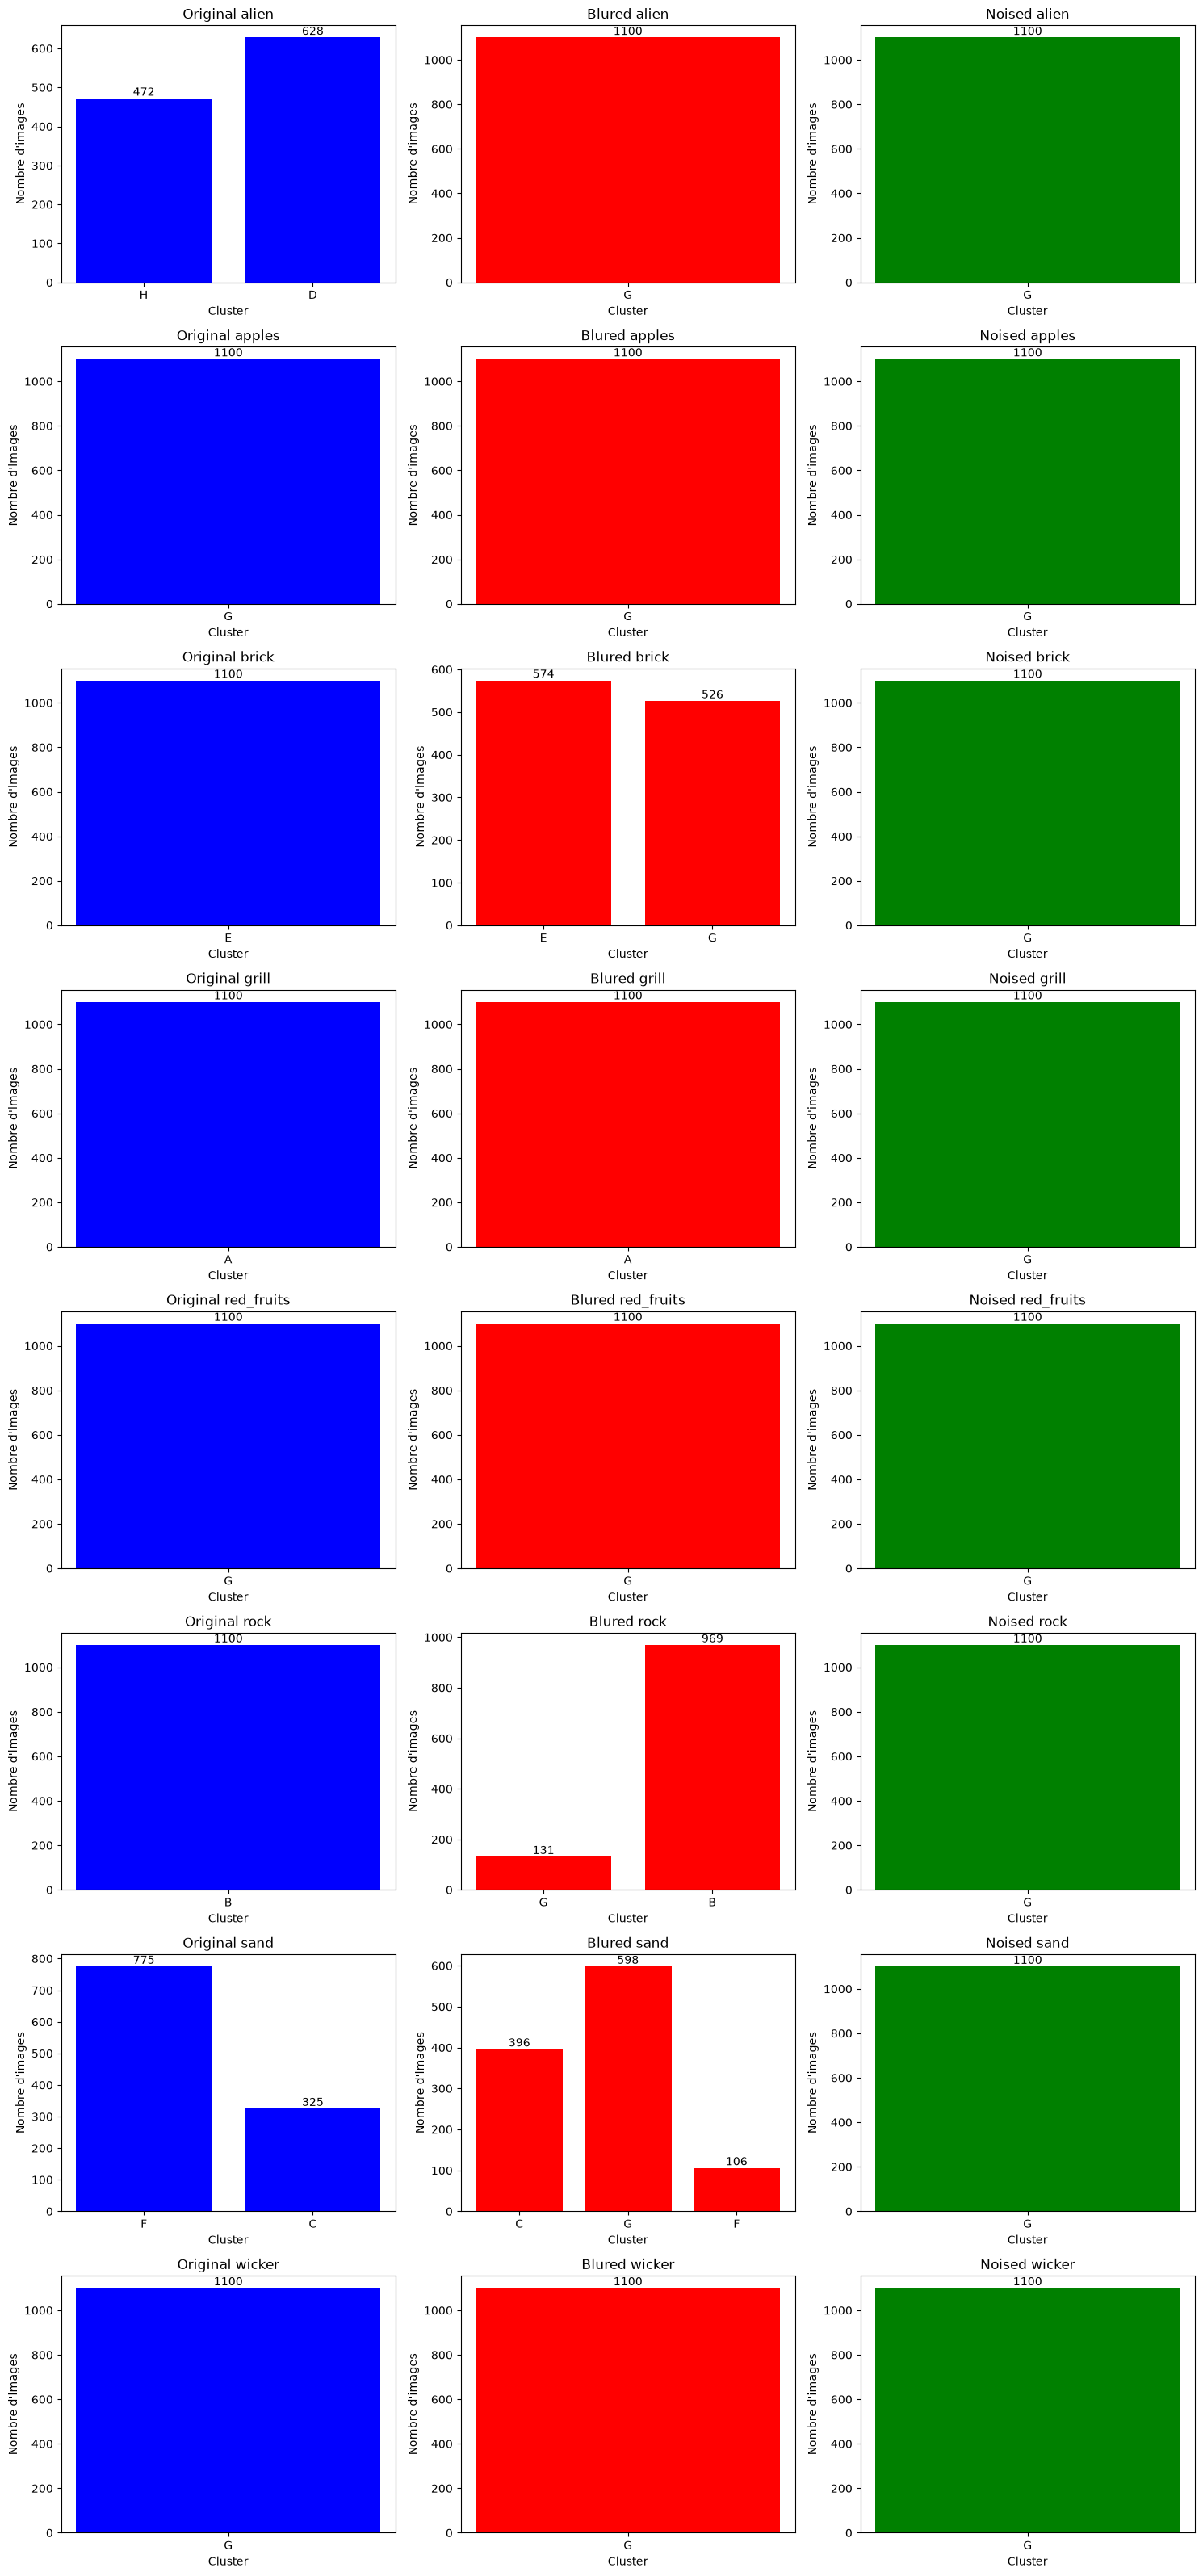

In [47]:
classes = ["alien", "apples", "brick", "grill", "red_fruits", "rock", "sand", "wicker"]
ig, axes = plt.subplots(len(classes), 3, figsize=(15, 4 * len(classes)))

for i, classe in enumerate(classes):
    PlotClassHisto(classe, clusters, PrepareData, "blue", axes[i, 0])
    PlotClassHisto(classe, clusters, PrepareBlurImage, "red", axes[i, 1])
    PlotClassHisto(classe, clusters, PrepareNoiseImage, "green", axes[i, 2])

    axes[i, 0].set_title("Original " + classe)
    axes[i, 1].set_title("Blured " + classe)
    axes[i, 2].set_title("Noised " + classe)

plt.tight_layout()
plt.show()

In [ ]:
def PlotImageHisto(chemin, transformations):
    originale = Image.open(chemin).convert("RGB")
    images = [("Originale", originale)]

    for titre, transformation in transformations:
        images.append((titre, transformation(originale.copy())))

    fig, axes = plt.subplots(
        3, len(images),
        figsize=(5 * len(images), 9),
        sharex=True,
        sharey=True
    )
    axes = np.array(axes).reshape(3, len(images))

    couleurs = ["red", "green", "blue"]
    noms = ["Rouge (R)", "Vert (G)", "Bleu (B)"]

    for colonne, (titre, image) in enumerate(images):
        pixels = np.array(image.convert("RGB"))

        for canal, (couleur, nom) in enumerate(zip(couleurs, noms)):
            ax = axes[canal, colonne]
            ax.hist(
                pixels[:, :, canal].ravel(),
                bins=256,
                range=(0, 256),
                color=couleur,
                histtype="step"
            )
            if colonne == 0:
                ax.set_ylabel(nom)
            if canal == 0:
                ax.set_title(titre)
            if canal == 2:
                ax.set_xlabel("Intensité des pixels")

    plt.tight_layout()
    plt.show()

for classe in classes : 
    PlotImageHisto(
        "Data/Generated/"+classe+".png",
        [
            ("Blured", BlurImage),
            ("Noised", NoiseImage),
        ]
    )

FileNotFoundError: [Errno 2] No such file or directory: 'Data/Generated/alien/alien.png'

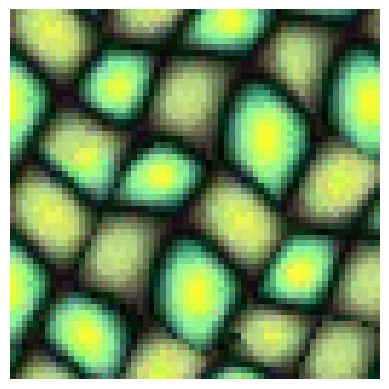

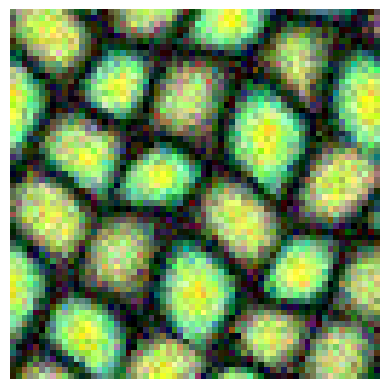

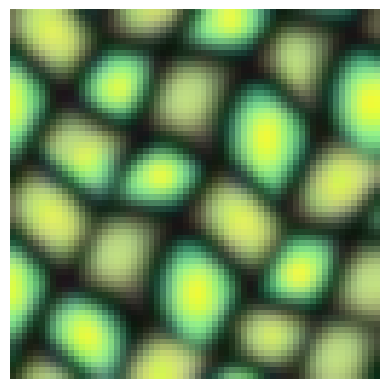

In [ ]:
plt.imshow(Image.open("Data/Classification/Test/alien_100.png"))
plt.axis("off")
plt.show()

plt.imshow(NoiseImage(Image.open("Data/Classification/Test/alien_100.png")))
plt.axis("off")
plt.show()

plt.imshow(BlurImage(Image.open("Data/Classification/Test/alien_100.png")))
plt.axis("off")
plt.show()